# 03 · Pulser, front end, ADC timing and the PIC programmer

The remaining commands: a pulser shot without a capture, the I²C bus, the PIC's op amps, an ADC timing experiment,
and the RP's built-in programmer for the PIC32AK.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "library"))   # the minus package (or: pip install -e python/library)
import warnings
warnings.filterwarnings("ignore", message="Unable to import Axes3D")   # harmless on mixed matplotlib installs
import numpy as np
import matplotlib.pyplot as plt
from minus import Minus, MinusError
import minus
print("library", minus.__version__, "written for firmware", minus.FIRMWARE)

library 1.1.9 written for firmware {'rp': {'name': 'minus-rp2354', 'version': '1.1.9'}, 'pic': {'name': 'minus-pic32', 'version': '1.1.6'}, 'proto': 15}


In [2]:
dev = Minus()

## 1. `pulse`: one shot, no capture

Use it with a scope on the TX node. The reply gives the timing actually programmed (the PIO runs at clk_sys, so
the widths are rounded to its cycle).

In [3]:
p = dev.pulse(100, 500, 27)
dev.last.show()
p

>>> pulse 100 500 27
<<< pulse: +5V 100.0 ns, off 26.7 ns, GND 500.0 ns, then released (clk_sys 150 MHz)
<<< fired
    (2 lines, 1 ms)


Pulse(hi_ns=100.0, dead_ns=26.7, lo_ns=500.0, clk_sys_mhz=150, fired=True)

In [4]:
for hi in (13, 50, 113, 200, 400):
    p = dev.pulse(hi, 500)
    print(f"asked {hi:4d} ns -> +5V {p.hi_ns:6.1f} ns, dead {p.dead_ns:4.1f} ns, GND {p.lo_ns:6.1f} ns, fired={p.fired}")

asked   13 ns -> +5V   13.3 ns, dead 26.7 ns, GND  500.0 ns, fired=True
asked   50 ns -> +5V   53.3 ns, dead 26.7 ns, GND  500.0 ns, fired=True
asked  113 ns -> +5V  113.3 ns, dead 26.7 ns, GND  500.0 ns, fired=True
asked  200 ns -> +5V  200.0 ns, dead 26.7 ns, GND  500.0 ns, fired=True
asked  400 ns -> +5V  400.0 ns, dead 26.7 ns, GND  500.0 ns, fired=True


## 2. I²C bus: `i2c`, `pot`

The RP is the only I²C master. Board v1.1 has the LP5562 LED driver at 0x30. The MCP4531 digipots (`pot`) were on
the devkit only, so `pot` raises `MinusError` here; the library passes on the board's NAK text.

In [5]:
scan = dev.i2c_scan(); dev.last.show(); scan

>>> i2c
<<<   0x30  LP5562 U5 (RGB LED driver)
<<< i2c scan: 1 device(s)
    (2 lines, 14 ms)


I2CScan(devices=[(48, 'LP5562 U5 (RGB LED driver)')])

In [6]:
try:
    dev.pot(0)
except MinusError as e:
    print("MinusError:", e)

MinusError: pot -> pot 0: read NAK (no device at 0x2E?)


## 3. The PIC's op amps: `raw AMP1 0|1`, `raw AMP2 0|1`

Plain link commands, forwarded with `raw`. The PIC echoes the new state.

In [7]:
print("AMP1 on:", dev.amp1(True)); dev.last.show()

AMP1 on: True
>>> raw AMP1 1
<<< reply: 'AMP1 1'
    (1 lines, 4 ms)


In [8]:
print("AMP2 off:", dev.amp2(False)); print("AMP2 on: ", dev.amp2(True))   # OA2 = the second gain stage, on at boot

AMP2 off: False
AMP2 on:  True


## 4. ADC timing experiment: `raw ADCBB n [ovs]`

Times `n` back-to-back conversions on the PIC (no DMA). The reply is `ADCBB n ovs ticks tick_ns data`:

In [9]:
for n in (10, 100, 1000):
    r = dev.adcbb(n)
    print(f"{r.raw:28} -> {r.ns_per_conversion:5.1f} ns per conversion (Timer1 resolution {r.tick_ns} ns)")

                             ->  56.0 ns per conversion (Timer1 resolution 80 ns)
                             ->  33.6 ns per conversion (Timer1 resolution 80 ns)
                             ->  32.2 ns per conversion (Timer1 resolution 80 ns)


### Experimental capture paths: `acqcpu`, `acqil`

Kept from the devkit throughput study (memory 0011): `acqcpu` reads the ADC from a CPU loop instead of DMA, `acqil`
interleaves two ADC channels (parked since the 200 MHz clock change: two 2-sums no longer fit one trigger period). Both are
diagnostics, not capture modes; `acqil` changes the PIC's trigger divider, so a normal `acq` follows.

In [10]:
c = dev.acqcpu(12, 1, 0, 0); print("acqcpu:", c.n, "samples,", c.note[:80])
try:
    c = dev.acqil(24, 0, 2); print("acqil: ", c.n, "values, fill", c.fill_us, "us")
except Exception as e:
    print("acqil: ", e)
dev.acq(4, 0, 25, 1);

acqcpu: 4095 samples, CPU-loop reader (no DMA, +0 NOPs per read, phase 0), trigger 12 (12 = SCCP1 at t
acqil:  4094 values, fill 495.0 us


## 5. Payload link (SPI) and the PIC DAC test signal — proto 11/12

Since rp 1.1.4 / pic 1.1.1 the PIC no longer pushes a capture over the 115 200 Bd UART (0.71 s): the RP pulls it as one
CRC-checked **SPI frame** (PIC = SPI1 client, SPI mode 1, 12.5 MHz default = 5.7 ms per capture; 18.75 and 25 MHz also
clean since rp 1.1.5 / pic 1.1.2, which announce the frame on RDY instead of a UART reply), with the UART as fallback. `link()` shows the path and counters, `linktest()` checks the link with a pattern from the PIC
(no capture, no piezo needed). Design: `docs/claude/specs/2026-11-21-dac-spi-link-design.md`.

In [11]:
s = dev.link("spi", 12.5); dev.last.show(); s

>>> link spi 12.5
<<< link: payload over SPI (UART fallback); SPI0 12.500 MHz (PIC client max 25 MHz); frames ok=1294 frame errors=0 uart fallbacks=0 no-reply=0; last frame 8202 B in 5717 us (1435 kB/s, incl. the SPIX request)
    (1 lines, 2 ms)


LinkStatus(spi=True, mhz=12.5, frames=1294, frame_errors=0, fallbacks=0, no_reply=0, last_bytes=8202, last_us=5717)

In [12]:
t = dev.linktest(20); dev.last.show()
print("passed:", t.passed, f"- {t.mean_us/1000:.1f} ms per 8202-byte frame ({t.kbytes_per_s:.0f} kB/s) vs 710 ms over the UART")

>>> linktest 20
<<< linktest: 20 frames of 8202 B at 12.500 MHz: ok=20 frame errors=0 pattern errors=0 frames / 0 words, no reply=0
<<< linktest: SPIX request+frame 5706 us mean (min 5705, max 5718) = 1437 kB/s; wire time alone 5249 us; 20 frames in 0.20 s
<<< linktest: of which SPIX -> RDY 455 us, SPI clocking 5251 us (mean)
<<< linktest: same buffer over the UART: identical (0 word errors) in 0.71 s
    (4 lines, 910 ms)
passed: True - 5.7 ms per 8202-byte frame (1437 kB/s) vs 710 ms over the UART


The PIC's **DAC1** drives DACOUT1 (U9 pin 3, H6.16 on board 3; the same pin is ADC2 input AD2AN3 = `acq` input 19),
so the capture path can be checked with a known waveform. `dac("tri", lo, hi, slope)` is a hardware triangle (no bus
traffic, safe during a capture); `dac("sine", hz, amp, mid)` is fed by DMA and makes 20–25 Msps captures come back
'slow' while it runs (bench 2026-11-21). Codes 205..3890 = 5..95 % of 3.3 V.

>>> dac tri 512 3584 16
<<< dac: triangle 512..3584 (0.413..2.888 V), slope 16 (12.4 counts per 4 ns step) -> period ~24.58 us (40.69 kHz, nominal)
<<<   read it back: acq 4 0 19   (AD2AN3 = DACOUT1, U9 pin 3; board 3: H6.16)
    (2 lines, 7 ms)
Dac(mode='tri', code=None, lo=512, hi=3584, slope=16, period_us=24.58, hz=None, points=None, update_us=None, amp=None, mid=None)
spi@12.50MHz 5717 us, 4095 samples, min/max 545 3513


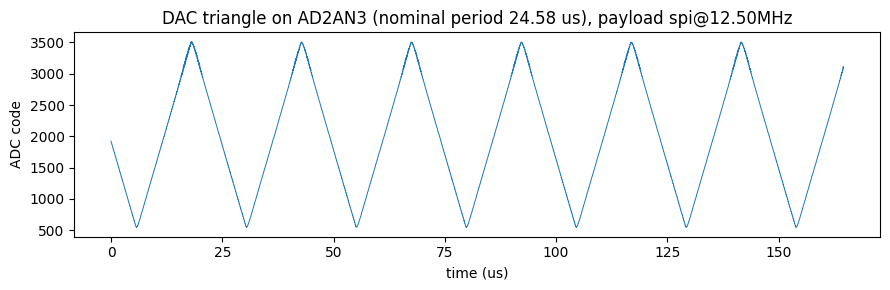

In [13]:
import matplotlib.pyplot as plt
d = dev.dac("tri", 512, 3584, 16); dev.last.show(); print(d)
c = dev.acq(4, 0, 19, 1)                      # 25 Msps on AD2AN3 = DACOUT1
print(c.link, f"{c.xfer_us} us,", c.n, "samples, min/max", c.samples.min(), c.samples.max())
plt.figure(figsize=(9, 3)); plt.plot(c.t_us, c.samples, lw=0.7)
plt.xlabel("time (us)"); plt.ylabel("ADC code"); plt.title(f"DAC triangle on AD2AN3 (nominal period {d.period_us:.2f} us), payload {c.link}")
plt.tight_layout(); plt.show()

In [14]:
print(dev.dac("off")); print(dev.link())

Dac(mode='off', code=None, lo=None, hi=None, slope=None, period_us=None, hz=None, points=None, update_us=None, amp=None, mid=None)


LinkStatus(spi=True, mhz=12.5, frames=1315, frame_errors=0, fallbacks=0, no_reply=0, last_bytes=8202, last_us=5717)


## 6. The PIC programmer (`pic …`)

The RP2354A carries the PIC firmware image and can program the PIC itself over ICSP (no Microchip tool needed).
`pic image` shows the embedded image and `pic id` reads the device ID. **Both reset the PIC**, so its settings
(`gain` bypass, `pc`) go back to their boot values.

In [15]:
img = dev.pic_image(); dev.last.show(); img

>>> pic image
<<< image 'minus_pic.hex': 5 segment(s), 35248 bytes
<<<   0x7f3010 +16 config (UCA/UCB)
<<<   0x7f3030 +16 config (UCA/UCB)
<<<   0x7f3810 +16 config (UCA/UCB)
<<<   0x7f3830 +16 config (UCA/UCB)
<<<   0x800000 +35184 code
    (6 lines, 1 ms)


PicImage(name='minus_pic.hex', nbytes=35248, segments=[(8335376, 16, 'config (UCA/UCB)'), (8335408, 16, 'config (UCA/UCB)'), (8337424, 16, 'config (UCA/UCB)'), (8337456, 16, 'config (UCA/UCB)'), (8388608, 35184, 'code')])

In [16]:
r = dev.pic_id(); dev.last.show(); r

>>> pic id
<<< ICSP pair 1 fast, 276 PGC clocks. DEVID 0x9da2 DEVREV 2 -> PIC32AK1216GC41048
<<< ICSP exit, PIC released (MCLR Hi-Z)
    (2 lines, 6 ms)


PicProg(devid=40354, devrev=2, part='PIC32AK1216GC41048', erase_ok=None, program_ok=None, verify_ok=None, bad_words=None, total_words=None, lines=['ICSP pair 1 fast, 276 PGC clocks. DEVID 0x9da2 DEVREV 2 -> PIC32AK1216GC41048', 'ICSP exit, PIC released (MCLR Hi-Z)'])

In [17]:
v = dev.pic_verify(); dev.last.show()
print("verify ok:", v.verify_ok, f"({v.bad_words} bad of {v.total_words} words)")

>>> pic verify
<<< ICSP pair 1 fast, 276 PGC clocks. DEVID 0x9da2 DEVREV 2 -> PIC32AK1216GC41048
<<< verify: ok (0 bad words of 8812)
<<< ICSP exit, PIC released (MCLR Hi-Z)
    (3 lines, 350 ms)
verify ok: True (0 bad of 8812 words)


To (re)flash the PIC with the image embedded in the RP firmware (~1 s: erase, program, verify, run). The PIC restarts,
so its op amps go back to their boot state: set the gain again afterwards. (`pic_erase()` alone leaves the PIC blank until the
next `pic_flash()` — not run here.)

In [18]:
print(dev.pic_help()[:400], "...")
r = dev.pic_flash(); print("flash ok:", r.ok, "| verify:", r.verify_ok, f"({r.bad_words} bad of {r.total_words} words)")
print(dev.pic_ident(), dev.pic_lock()); dev.gain(0, 1, 0);

pic pins    read PGC/PGD/MCLR/RDY/UART_RX levels (who drives what)
pic mclr low|hiz   hold the MCLR tap low for a meter check / release it
pic mclr rise      measure the MCLR node rise time after release (< 5 us = C31 really off)
pic slow|fast      ICSP clock ~100 kHz / ~1.2 MHz (diagnostic; default fast)
pic rdraw [addr [idle [nbits [ncmd]]]]  diagnostic: raw CMDSEQRD bit streams (defaults DEVID  ...


flash ok: True | verify: True (0 bad of 8812 words)
PicIdent(part='PIC32AK1216GC41048', name='minus-pic32', version='1.1.6', proto=15) PicLock(tries=3, slow=0)


## 7. Diagnostics and reboot

`pic_pins()`, `pic_mclr("rise")` and `raw_cli("pic rdraw …")` are bring-up diagnostics. `reboot(dfu=True)` puts
the RP into its UF2 bootloader to load a new `.uf2`. It closes the port, so reconnect afterwards. Not run here:

```python
dev.reboot(dfu=True)      # a UF2 drive appears; copy firmware/rp2354/build/minus_rp.uf2 onto it
```

In [19]:
for ln in dev.pic_pins():
    print(ln)

  PGC1/GPIO21     level=0  with pull-up=1  with pull-down=0  -> floating (nothing drives it)
  PGD1/GPIO22     level=0  with pull-up=1  with pull-down=0  -> floating (nothing drives it)
  MCLR/GPIO24     level=1  with pull-up=1  with pull-down=1  -> driven HIGH externally
  RDY/GPIO7       level=0  with pull-up=0  with pull-down=0  -> driven LOW externally
  UART_RX/GPIO17  level=1  with pull-up=1  with pull-down=1  -> driven HIGH externally
note: RP SWD pad pulls are OFF (fw >= 0.1.6); a blank PIC leaves PGC1/PGD1 floating. MCLR must be HIGH via R5.


In [20]:
print(dev.pic_icsp_speed(True)); print(dev.pic_icsp_speed(False))       # ICSP clock ~100 kHz / ~1.2 MHz (default)
for ln in dev.pic_mclr("rise"): print(ln)                                 # MCLR rise time (the PIC restarts)
print(dev.pic_ident()); dev.gain(0, 1, 0);

ICSP clock: slow (~100 kHz)
ICSP clock: fast (~1.2 MHz)
MCLR rise after release: 5 us -> C31 is off the node (JP1 cut OK)


PicIdent(part='PIC32AK1216GC41048', name='minus-pic32', version='1.1.6', proto=15)


`reboot()` restarts the RP (the serial port disappears and comes back: reconnect with a new `Minus()`); `reboot(dfu=True)`
enters the UF2 bootloader for a firmware update. Not run here: on 2026-11-22, with the transducer connected, `reboot dfu` twice
left the board off USB until it was replugged with BOOTSEL held (datasheet E8).

In [21]:
dev.close()